# The open-source streamlined data access API in CDSE:**openEO API**

**CASSINI warm-up | EU Space for Peace and Resilience**

> **Open Question:** "You have a useful idea and one weekend. How much time do you want to spend finding and downloading satellite images? And how much in generating a reuseable and scalable workflow?"



The **Copernicus Data Space Ecosystem** facilitates cloud processing of Earth Observation (EO) data through its streamlined data access APIs, including the openEO API.

Content:
1. What is openEO? Why use it? How to get started?
2. What is the openEO agent?
3. A simple workflow example: August 2026 Flood Event in Nepal
4. openEO in QGIS


So will be **understand about openEO → get help using openEO agaent to build a openEO workflow → inspect the result → bring it into QGIS.**

### Introduction to openEO

openEO is an open-source initiative that simplifies accessing and processing Earth Observation (EO) data.

Traditional methods involve complex steps like data discovery, download, and pre-processing, which can be time-consuming and challenging, especially when dealing with multiple datasets. openEO standardises this process, providing a unified interface for accessing and processing diverse EO datasets using familiar programming languages like Python. It leverages the concept of datacubes, which streamline the representation and manipulation of EO data, making spatiotemporal analysis more intuitive and efficient.

Thus **openEO is an open, standard API for accessing and processing Earth observation data in the cloud.** Python is one way to describe the analysis; the backend performs the satellite processing.

#### Main concepts to remember when using openEO
- **Data cube:** the multidimensional view of the observations.
- **Process graph:** a JSON recipe connecting inputs and operations.
- **Backend:** the service that executes that recipe near the data.

[Cubes&Cloud](https://eo-college.org/courses/cubes-and-clouds/)
[openEO community example](https://github.com/Open-EO/openeo-community-examples/tree/main/python)

<table border="0" cellspacing="0" cellpadding="0" style="width: 100%; table-layout: fixed; border: none !important; background: transparent !important;">
  <tr style="border: none !important; background: transparent !important;">
    <td width="55%" valign="top" style="border: none !important; background: transparent !important; padding: 0 24px 0 0; text-align: left;">
      <h4>Added Value with openEO</h4>
      <ul>
        <li><strong>Unified</strong> and <strong>straightforward</strong> access &amp; processing to multiple Earth observation datasets</li>
        <li><strong>Scalable</strong> processing</li>
        <li>A <strong>standardized</strong> system that makes different platforms <strong>Interoperable</strong></li>
        <li><strong>Independence</strong> from underlying technologies and software libraries</li>
        <li><strong>FAIR</strong> and <strong>open-science</strong> principles</li>
      </ul>
      <p>Hence, by adopting openEO, developers, researchers, and data scientists can efficiently use distributed computing environments and cloud-based resources to tackle complex geospatial challenges.</p>
    </td>
    <td width="45%" valign="middle" style="border: none !important; background: transparent !important; padding: 0;">
      <img src="openeo.png" alt="openEO diagram" style="width: 100%; height: auto;" />
    </td>
  </tr>
</table>

### How to get started


**Connect → discover → load/filter → process → execute → download results.**

| Step | Python entry point | What to explain |
|---|---|---|
| Connect and authenticate | `openeo.connect(...).authenticate_oidc()` | Select a backend and sign in. |
| Discover data | `connection.list_collection_ids()` / `describe_collection(...)` | Check available collections, bands and coverage. |
| Discover processes | `connection.list_processes()` / `describe_process(...)` | Check the list of available processes on the backend. |
| Load and filter | `connection.load_collection(...)` | Select a small area, time window and necessary bands early. |
| Process | `.band(...)`, band arithmetic, `.median_time()` | Analyse the data cube to derive indices or aggregated values. |
| Execute | `.download(...)` or create/start a batch job | This is when satellite processing is requested. |

In [ ]:
# import openeo
import openeo

# connect to the needed backend
connection = openeo.connect("openeo.dataspace.copernicus.eu")

# authenticate with the backend
connection.authenticate_oidc()

cube = connection.load_collection(
    "SENTINEL2_L2A",
    spatial_extent={"west": 0, "south": 0, "east": 1, "north": 1},
    temporal_extent=["2024-01-01", "2024-12-31"],
    bands=["B04", "B08"],
)

# apply openeo processes
ndvi_v1 = cube.ndvi(red="B04", nir="B08")

# Alternatively: use band math for NDVI
red, nir = cube.band("B04"), cube.band("B08")
ndvi_v2 = (nir - red) / (nir + red)
composite = ndvi_v2.median_time()

# execute the processing and download the result
composite.download("ndvi_composite.tif")

# Alternatively for large jobs
job = composite.execute_batch(title="NDVI Composite Job", outputfile="ndvi_composite.tif")

### Meet the openEO agent: a helper for building openEO workflows

The [openEO agent](https://chat.openeo.vito.be) helps translate a question into an **editable openEO workflow**. It was announced in October 2026 and is currently limited to the **CDSE backend and Python client** only. 


- You provide the question, area, dates, and constraints to the agent.
- The agent proposes a workflow based on your input.
- You review and approve the proposed workflow before execution.
- The agent assists with monitoring and troubleshooting the job.

#### Demonstrating Nepal flood recovery from space

On **26 August 2026**, a glacier/rock-collapse-related flood and debris flow occurred. In this example, we focus on a small downstream section around **Timure and Syabrubesi**.

This supports the **civil-resilience component of Challenge #2: Space-enabled crisis response and civil resilience**. Nepal is a natural-disaster analogue demonstrating a reusable method, not a conflict-damage case.

Let us ask openeo-agent to help us analyze the flood recovery in the Timure and Syabrubesi area.

The following code was suggested by openeo-agent.

In [1]:
# connect to OpenEO backend
import openeo

# Connect to the OpenEO backend
connection = openeo.connect("openeo.dataspace.copernicus.eu").authenticate_oidc()

Authenticated using refresh token.


In [2]:
# load the collection
def input_cube(connection, dates):
    cube = connection.load_collection(
        "SENTINEL2_L2A", 
        spatial_extent={"west": 85.30, "south": 28.12, "east": 85.42, "north": 28.30}, 
        temporal_extent=dates,
        bands=["B02", "B03", "B04", "B08"],
    )
    scl = connection.load_collection(
        "SENTINEL2_L2A", 
        spatial_extent={"west": 85.30, "south": 28.12, "east": 85.42, "north": 28.30}, 
        temporal_extent=dates,
        bands=["SCL"],
    )
    # Mask cloud shadow (3), cloud medium prob (8), cloud high prob (9), thin cirrus (10)
    cloud_mask = (
        (scl == 3) | (scl == 8) | (scl == 9) | (scl == 10)
    )
    masked = cube.mask(cloud_mask)
    return masked

pre_cube = input_cube(connection, ["2026-07-26", "2026-08-26"])
post_cube = input_cube(connection, ["2026-08-27", "2026-10-01"])

In [3]:
# rgb composite for pre and post cubes
pre_rgb = pre_cube.filter_bands(["B04", "B03", "B02"]).median_time()
post_rgb = post_cube.filter_bands(["B04", "B03", "B02"]).median_time()

# ndvi for pre and post cubes
pre_ndvi = pre_cube.ndvi(nir="B08", red="B04")
post_ndvi = post_cube.ndvi(nir="B08", red="B04")

#composite NDVI for pre and post cubes
pre_composite = pre_ndvi.median_time()
post_composite = post_ndvi.median_time()

In [4]:
# save each as individual files
from openeo import MultiResult
pre_rgb_result = pre_rgb.save_result(format="GTiff", options={"filename_prefix": "pre_rgb"})
post_rgb_result = post_rgb.save_result(format="GTiff", options={"filename_prefix": "post_rgb"})
pre_ndvi_result = pre_composite.save_result(format="GTiff", options={"filename_prefix": "pre_composite"})
post_ndvi_result = post_composite.save_result(format="GTiff", options={"filename_prefix": "post_composite"})

multiresult_rgb_ndvi = MultiResult([pre_rgb_result, post_rgb_result, pre_ndvi_result, post_ndvi_result])
rgb_ndvi_job = multiresult_rgb_ndvi.create_job(title="Multiple save result RGB and NDVI")
rgb_ndvi_job.start_and_wait()

0:00:00 Job 'j-2611121322474e82b3542cb9bbfc062b': send 'start'
0:00:02 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:07 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:14 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:22 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:31 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:44 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:00:59 Job 'j-2611121322474e82b3542cb9bbfc062b': queued (progress 0%)
0:01:18 Job 'j-2611121322474e82b3542cb9bbfc062b': running (progress N/A)
0:01:42 Job 'j-2611121322474e82b3542cb9bbfc062b': running (progress N/A)
0:02:12 Job 'j-2611121322474e82b3542cb9bbfc062b': running (progress N/A)
0:02:50 Job 'j-2611121322474e82b3542cb9bbfc062b': running (progress N/A)
0:03:36 Job 'j-2611121322474e82b3542cb9bbfc062b': finished (progress 100%)


<BatchJob job_id='j-2611121322474e82b3542cb9bbfc062b'>

In [5]:
results = rgb_ndvi_job.get_results()
results.download_files("data/rgb_ndvi_job")

[WindowsPath('data/rgb_ndvi_job/post_composite.tif'),
 WindowsPath('data/rgb_ndvi_job/post_rgb.tif'),
 WindowsPath('data/rgb_ndvi_job/pre_composite.tif'),
 WindowsPath('data/rgb_ndvi_job/pre_rgb.tif'),
 WindowsPath('data/rgb_ndvi_job/job-results.json')]

pre: excluded 317 out-of-range NDVI pixels
post: excluded 1,700 out-of-range NDVI pixels


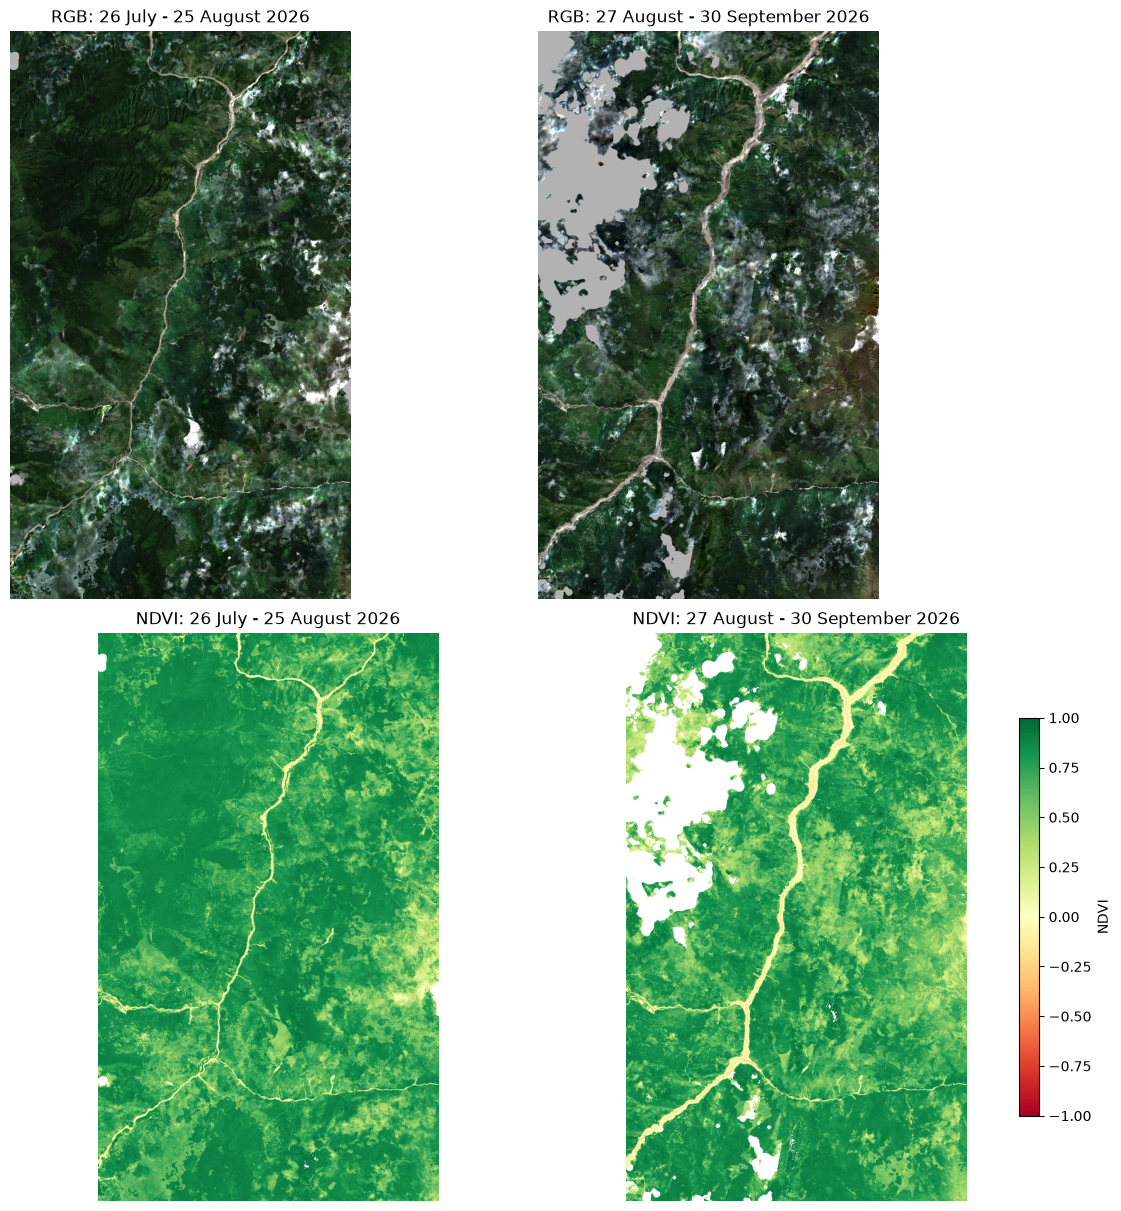

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

folder = Path("data") / "rgb_ndvi_job"
fig, axes = plt.subplots(2, 2, figsize=(12, 12), constrained_layout=True)
for column, (period, dates) in enumerate([
    ("pre", "26 July - 25 August 2026"),
    ("post", "27 August - 30 September 2026"),
]):
    with rasterio.open(folder / f"{period}_rgb.tif") as src:
        rgb = src.read(masked=True).astype("float32").filled(np.nan)
    rgb = np.moveaxis(rgb, 0, -1) / 3000
    rgb[~np.isfinite(rgb).all(axis=2)] = 0.7
    axes[0, column].imshow(np.clip(rgb, 0, 1))
    axes[0, column].set_title(f"RGB: {dates}")

    with rasterio.open(folder / f"{period}_composite.tif") as src:
        ndvi = np.ma.masked_invalid(src.read(1, masked=True))
    invalid = (np.abs(ndvi.data) > 1) & ~np.ma.getmaskarray(ndvi)
    print(f"{period}: excluded {invalid.sum():,} out-of-range NDVI pixels")
    ndvi = np.ma.masked_where(invalid, ndvi)
    image = axes[1, column].imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
    axes[1, column].set_title(f"NDVI: {dates}")

fig.colorbar(image, ax=axes[1, :], shrink=0.7, label="NDVI")
for ax in axes.flat:
    ax.set_facecolor("0.7")
    ax.set_axis_off()
plt.show()

### Results into QGIS


The **openEO QGIS plugin** uses the backend API to browse and load results into QGIS. This is a desktop handoff, not a separate satellite-processing workflow.

- Connect to the same backend/account, browse completed batch jobs and add supported result assets directly as QGIS layers.
- Combine the outputs with roads, bridges or other context for further analysis and map-making.

More information: [official QGIS plugin documentation](https://openeo.org/documentation/1.0/qgis/). The QGIS demonstration is separate; the notebook plots remain the result-viewing step here.